# Band noise iniettato a log10_A = -14, analisi con il modello STANDARD

Dati: `sim_data_noise_bn_A140_sv44/`, generati da `Simulations_bandnoise_A140_sv44.ipynb`.

Valori iniettati:

| componente | gamma | log10_A |
|---|---|---|
| red_noise | 0.1324 | -13.213 |
| dm_gp (alpha = 2) | 6.471 | -15.723 |
| sv_gp (alpha = 4.4) | 1.326 | -15.888 |
| **band_noise** (LOFAR, 40 comp.) | **3.0** | **-14.0** |

Qui l analisi usa il **modello standard a 6 parametri**, con `sv_gp` ad alpha = 4.4 e **nessun termine
di band noise**. Il band noise c e nei dati ma non nel modello: e il modello sbagliato, ed e
esattamente il punto.

Domande:

1. Dove finisce la potenza del band noise, che il modello non sa rappresentare? Viene assorbita da
   `sv_gp`, da `dm_gp`, dal `red_noise`?
2. Di quanto si spostano i parametri dai valori veri, e in unita di quante sigma?
3. Il confronto con la stessa analisi su dati senza band noise (`test_sim_sv44_alpha44`) mostra uno
   spostamento riconoscibile?

Se il band noise viene assorbito da `sv_gp` o sposta i parametri del DM, hai dimostrato **su dati
dove la verita la conosci** lo stesso meccanismo di degenerazione che sospetti nei dati reali.

Il notebook con il band noise anche nella recovery e il 17.


## Setup comune

Copia delle celle 0, 1, 3, 4, 6, 7, 9 di `Likelihood.ipynb`. `psr` e la pulsar **reale** e
`logL.params` (6 parametri) serve da riferimento per l ordine delle colonne.


In [22]:
import numpy as np
import os, glob, json
import pickle

import sys

# this is the path to the discovery folder
sys.path.insert(0, "./")
import discovery_new as ds

import matplotlib.pyplot as plt
import scipy
import jax.numpy as jnp

from scipy.stats import uniform
import re
from PTMCMCSampler.PTMCMCSampler import PTSampler as ptmcmc
from scipy.stats import uniform
import jax

import time
import emcee

In [23]:
# path to the folder with the data
path = './dati/DR2low_feathers/'
s_dsfiles = np.sort(os.listdir(path))
psr = [ds.pulsar.Pulsar.read_feather(path + f'{psrfile}') for psrfile in s_dsfiles][9] # we are only analysing pulsar #9

In [24]:
# data
model = [psr.residuals]
# timing model
model += [ds.makegp_timing(psr, svd=True)]
# white noise parameters
model += [ds.makenoise_measurement(psr, psr.noisedict, tnequad = True, ecorr=True)]
# red noise paramters
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_red_components'], T=ds.getspan(psr), name='red_noise' ))
# DM variation parameters
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_dm_components'], T=ds.getspan(psr), name='dm_gp', fourierbasis=ds.make_dmfourierbasis(alpha = 2.0, tndm = False)))
# scattering noise parameters
model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_chrom_components'], T=ds.getspan(psr), name='sv_gp', fourierbasis=ds.make_dmfourierbasis(alpha = 4.0, tndm = False)))

In [25]:
logL = ds.PulsarLikelihood(model).logL

In [26]:
def params_dict_from_array(x):
    x = np.asarray(x)
    return dict(zip(logL.params, x))

In [27]:
##### Cell for the prior distributions ###################################################################################

my_priordict = {}
my_priordict["(.*_)?sv_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?sv_gp_alpha.*"] = [0, 10]
my_priordict["(.*_)?sv_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_log10_A.*"] = [-10, 1]
my_priordict["(.*_)?sw_gamma.*"] = [-5, 6]
my_priordict["(.*_)?dm_gp_gamma.*"] = [0, 7]
my_priordict["(.*_)?dm_gp_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?red_noise_gamma.*"] = [0, 7]
my_priordict["(.*_)?red_noise_log10_A.*"] = [-20, -11]
my_priordict["(.*_)?sw_n_earth.*"] = [0, 30]


def build_priors(param_names, priordict):
    """
    Build a {param_name: scipy dist} dict with uniform prior distributions in the range
    """
    priors = {}
    unmatched = []
    for name in param_names:
        matched = False
        for pattern, (lo, hi) in priordict.items():
            if re.fullmatch(pattern, name):
                priors[name] = uniform(loc=lo, scale=hi - lo)
                matched = True
                break
        if not matched:
            unmatched.append(name)

    if unmatched:
        print(f"Warning: no prior found for {len(unmatched)} parameters, "
              f"falling back to standard normal:\n  {unmatched}")
    return priors

## Dati simulati con band noise

Controllo da fare per primo: lo scatter in eccesso rispetto ai dati reali deve concentrarsi nella
banda LOFAR, dove vive il band noise iniettato. Se e alto anche fuori, l iniezione non lo ha
confinato e non vale la pena lanciare il sampling.


In [28]:
bn_psr = ds.pulsar.Pulsar.read_feather('sim_data_noise_bn_A140_sv44/J1640+2224')
print('nome  :', bn_psr.name)
print('N_TOA :', len(bn_psr.toas))

# maschera della selezione LOFAR, la stessa usata nell iniezione
sel = ds.lofar_backends(bn_psr)
mask_lofar = np.any(np.vstack([np.asarray(m, dtype=bool) for m in sel.values()]), axis=0)
print(f'ToA LOFAR: {mask_lofar.sum()} su {len(bn_psr.toas)}')

print()
print(f"{'':22s} {'simulati':>12s} {'reali':>12s} {'rapporto':>10s}")
for etichetta, m in [('tutte', np.ones(len(bn_psr.toas), bool)),
                     ('LOFAR (121-185 MHz)', mask_lofar),
                     ('resto (>1 GHz)', ~mask_lofar)]:
    a, b = np.std(bn_psr.residuals[m]), np.std(psr.residuals[m])
    print(f'{etichetta:22s} {a:12.3e} {b:12.3e} {a/b:10.2f}')
print()
print('atteso: rapporto >> 1 in banda LOFAR, ~1 fuori.')

nome  : J1640+2224
N_TOA : 6777
ToA LOFAR: 5232 su 6777

                           simulati        reali   rapporto
tutte                     7.385e-05    4.973e-05       1.49
LOFAR (121-185 MHz)       8.388e-05    5.644e-05       1.49
resto (>1 GHz)            8.334e-06    7.645e-06       1.09

atteso: rapporto >> 1 in banda LOFAR, ~1 fuori.


In [29]:
# valori veri iniettati (band_noise compreso, anche se nel modello di analisi non c e)
truths_bn = {
    'J1640+2224_dm_gp_gamma': 6.471070651479037,
    'J1640+2224_dm_gp_log10_A': -15.7227863246785,
    'J1640+2224_red_noise_gamma': 0.13235259553929019,
    'J1640+2224_red_noise_log10_A': -13.212902548624186,
    'J1640+2224_sv_gp_gamma': 1.3259815720503758,
    'J1640+2224_sv_gp_log10_A': -15.888300265911965,
    'J1640+2224_band_noise_gamma': 3.0,
    'J1640+2224_band_noise_log10_A': -14.0,
}

## Modello standard a 6 parametri

`sv_gp` ad alpha = 4.4 come nell iniezione, **nessun termine di band noise**.


In [30]:
model_bn140 = [bn_psr.residuals]
model_bn140 += [ds.makegp_timing(bn_psr, svd=True)]
model_bn140 += [ds.makenoise_measurement(bn_psr, bn_psr.noisedict, tnequad=True, ecorr=True)]
model_bn140.append(ds.makegp_fourier(bn_psr, ds.powerlaw, bn_psr.noisedict[bn_psr.name + '_red_components'],
                                     T=ds.getspan(bn_psr), name='red_noise'))
model_bn140.append(ds.makegp_fourier(bn_psr, ds.powerlaw, bn_psr.noisedict[bn_psr.name + '_dm_components'],
                                     T=ds.getspan(bn_psr), name='dm_gp',
                                     fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_bn140.append(ds.makegp_fourier(bn_psr, ds.powerlaw, bn_psr.noisedict[bn_psr.name + '_chrom_components'],
                                     T=ds.getspan(bn_psr), name='sv_gp',
                                     fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))

logL_bn140 = ds.PulsarLikelihood(model_bn140).logL
assert set(logL_bn140.params) == set(logL.params), f'inatteso: {logL_bn140.params}'
print('OK: 6 parametri, nessun band noise nel modello')
logL_bn140.params

OK: 6 parametri, nessun band noise nel modello


['J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [31]:
def params_dict_from_array_bn140(x):
    x = np.asarray(x)
    return dict(zip(logL_bn140.params, x))

priors_bn140 = build_priors(logL_bn140.params, my_priordict)

def log_prior_bn140(x):
    params = params_dict_from_array_bn140(x)
    logp = 0.0
    for name, value in params.items():
        if name in priors_bn140:
            logp += priors_bn140[name].logpdf(value)
        else:
            logp += -0.5 * np.sum(np.asarray(value)**2)
    return logp

def prior_draw_bn140():
    return np.array([priors_bn140[name].rvs() for name in logL_bn140.params])

x0_bn140 = prior_draw_bn140()
print('x0 =', x0_bn140)

x0 = [  1.88916845 -19.6706851    5.26638253 -19.33093427   5.88041607
 -17.31082448]


In [32]:
@jax.jit
def _jit_logL_bn140(params_array):
    return logL_bn140(dict(zip(logL_bn140.params, params_array)))

def log_likelihood_bn140(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn140(jnp.array(x))))

print('logL iniziale =', log_likelihood_bn140(x0_bn140))

# tempo di una valutazione (dopo la compilazione): serve a stimare la durata del sampling
start = time.time()
for _ in range(20):
    log_likelihood_bn140(x0_bn140)
dt = (time.time() - start) / 20
print(f'una valutazione = {dt*1e3:.1f} ms  ->  10^6 iterazioni ~ {dt*1e6/3600:.1f} ore (solo likelihood)')
print('riferimento: con alpha fisso il notebook 10 misurava 1.0 ms, cioe ~0.3 ore per 10^6')

logL iniziale = 67500.53055721926
una valutazione = 1.4 ms  ->  10^6 iterazioni ~ 0.4 ore (solo likelihood)
riferimento: con alpha fisso il notebook 10 misurava 1.0 ms, cioe ~0.3 ore per 10^6


In [33]:
sampler_bn140 = ptmcmc(
    ndim=len(logL_bn140.params),
    logl=log_likelihood_bn140,
    logp=log_prior_bn140,
    cov=np.eye(len(logL_bn140.params)) * 0.001,
    outDir='./test_sim_bn_A140/',
    resume=True
)

### Sampling

Con alpha fisso una valutazione costa ~1-3 ms, quindi 10^6 iterazioni si fanno sul Mac in meno di
unoretta: si puo girare in locale, non serve mithrandir. Eseguire **una sola volta**; poi per rifare
i grafici saltare questa cella e ripartire da quella che legge `chain_1.txt`.


In [34]:
ESEGUI_SAMPLING = False   # True solo per (ri)lanciare davvero il campionamento

if ESEGUI_SAMPLING:
    print("Starting sampling (band noise iniettato a -14, analisi con modello STANDARD a 6 par)...")
    sampler_bn140.sample(x0_bn140, Niter=1000000, thin=10)
else:
    print('sampling saltato: mettere ESEGUI_SAMPLING = True per lanciarlo')

sampling saltato: mettere ESEGUI_SAMPLING = True per lanciarlo


## Catena e risultati


In [35]:
chain_path = './test_sim_bn_A140/chain_1.txt'

if not os.path.exists(chain_path):
    raise FileNotFoundError(
        f'catena non trovata: {chain_path}\n'
        'Mettere ESEGUI_SAMPLING = True nella cella sopra e lanciare il sampling.'
    )

chain_bn140 = np.loadtxt(chain_path)
n_tot = len(chain_bn140)
chain_bn140 = chain_bn140[n_tot//4:, :-4]   # 25% di burn-in, via le 4 colonne diagnostiche
print(f'righe nel file: {n_tot}  ->  campioni usati: {len(chain_bn140)}  ({100*n_tot/100000:.1f}% della run completa)')

tau = emcee.autocorr.integrated_time(chain_bn140, has_walkers=False, quiet=True)
ess = int(len(chain_bn140) / tau.max())
print('tau =', dict(zip([p.replace('J1640+2224_', '') for p in logL_bn140.params], np.round(tau, 1))))
print('Effective sample size =', ess)

idx = {name: i for i, name in enumerate(logL_bn140.params)}
idx

righe nel file: 100001  ->  campioni usati: 75001  (100.0% della run completa)
tau = {'dm_gp_gamma': np.float64(3.8), 'dm_gp_log10_A': np.float64(3.8), 'red_noise_gamma': np.float64(4.7), 'red_noise_log10_A': np.float64(4.0), 'sv_gp_gamma': np.float64(3.6), 'sv_gp_log10_A': np.float64(2.7)}
Effective sample size = 15806


{'J1640+2224_dm_gp_gamma': 0,
 'J1640+2224_dm_gp_log10_A': 1,
 'J1640+2224_red_noise_gamma': 2,
 'J1640+2224_red_noise_log10_A': 3,
 'J1640+2224_sv_gp_gamma': 4,
 'J1640+2224_sv_gp_log10_A': 5}

In [36]:
# quanto si spostano i parametri dai valori veri, in unita di sigma della posteriore
print(f"{'parametro':22s} {'vero':>9s} {'mediana':>9s} {'[16, 84]':>20s} {'shift':>8s}")
for name in logL_bn140.params:
    col = chain_bn140[:, idx[name]]
    q16, q50, q84 = np.percentile(col, [16, 50, 84])
    sigma = 0.5 * (q84 - q16)
    vero = truths_bn[name]
    shift = (q50 - vero) / sigma if sigma > 0 else np.nan
    flag = '  <-- assorbe il band noise?' if abs(shift) > 1.5 else ''
    print(f"{name.replace('J1640+2224_', ''):22s} {vero:9.3f} {q50:9.3f} "
          f"[{q16:8.3f},{q84:8.3f}] {shift:7.2f}s{flag}")
print()
print('shift in unita di sigma della posteriore. Il parametro che si sposta di piu dal valore vero')
print('e quello che sta assorbendo la potenza del band noise che il modello non sa rappresentare.')

parametro                   vero   mediana             [16, 84]    shift
dm_gp_gamma                6.471     5.709 [   4.735,   6.548]   -0.84s
dm_gp_log10_A            -15.723   -15.175 [ -15.551, -14.750]    1.37s
red_noise_gamma            0.132     0.262 [   0.075,   0.566]    0.53s
red_noise_log10_A        -13.213   -13.249 [ -13.329, -13.171]   -0.46s
sv_gp_gamma                1.326     1.152 [   0.940,   1.372]   -0.81s
sv_gp_log10_A            -15.888   -15.899 [ -15.941, -15.855]   -0.25s

shift in unita di sigma della posteriore. Il parametro che si sposta di piu dal valore vero
e quello che sta assorbendo la potenza del band noise che il modello non sa rappresentare.


### Corner a 6 parametri

In nero i valori veri iniettati. Uno scostamento sistematico dal nero e il bias indotto dal band
noise mancante nel modello.


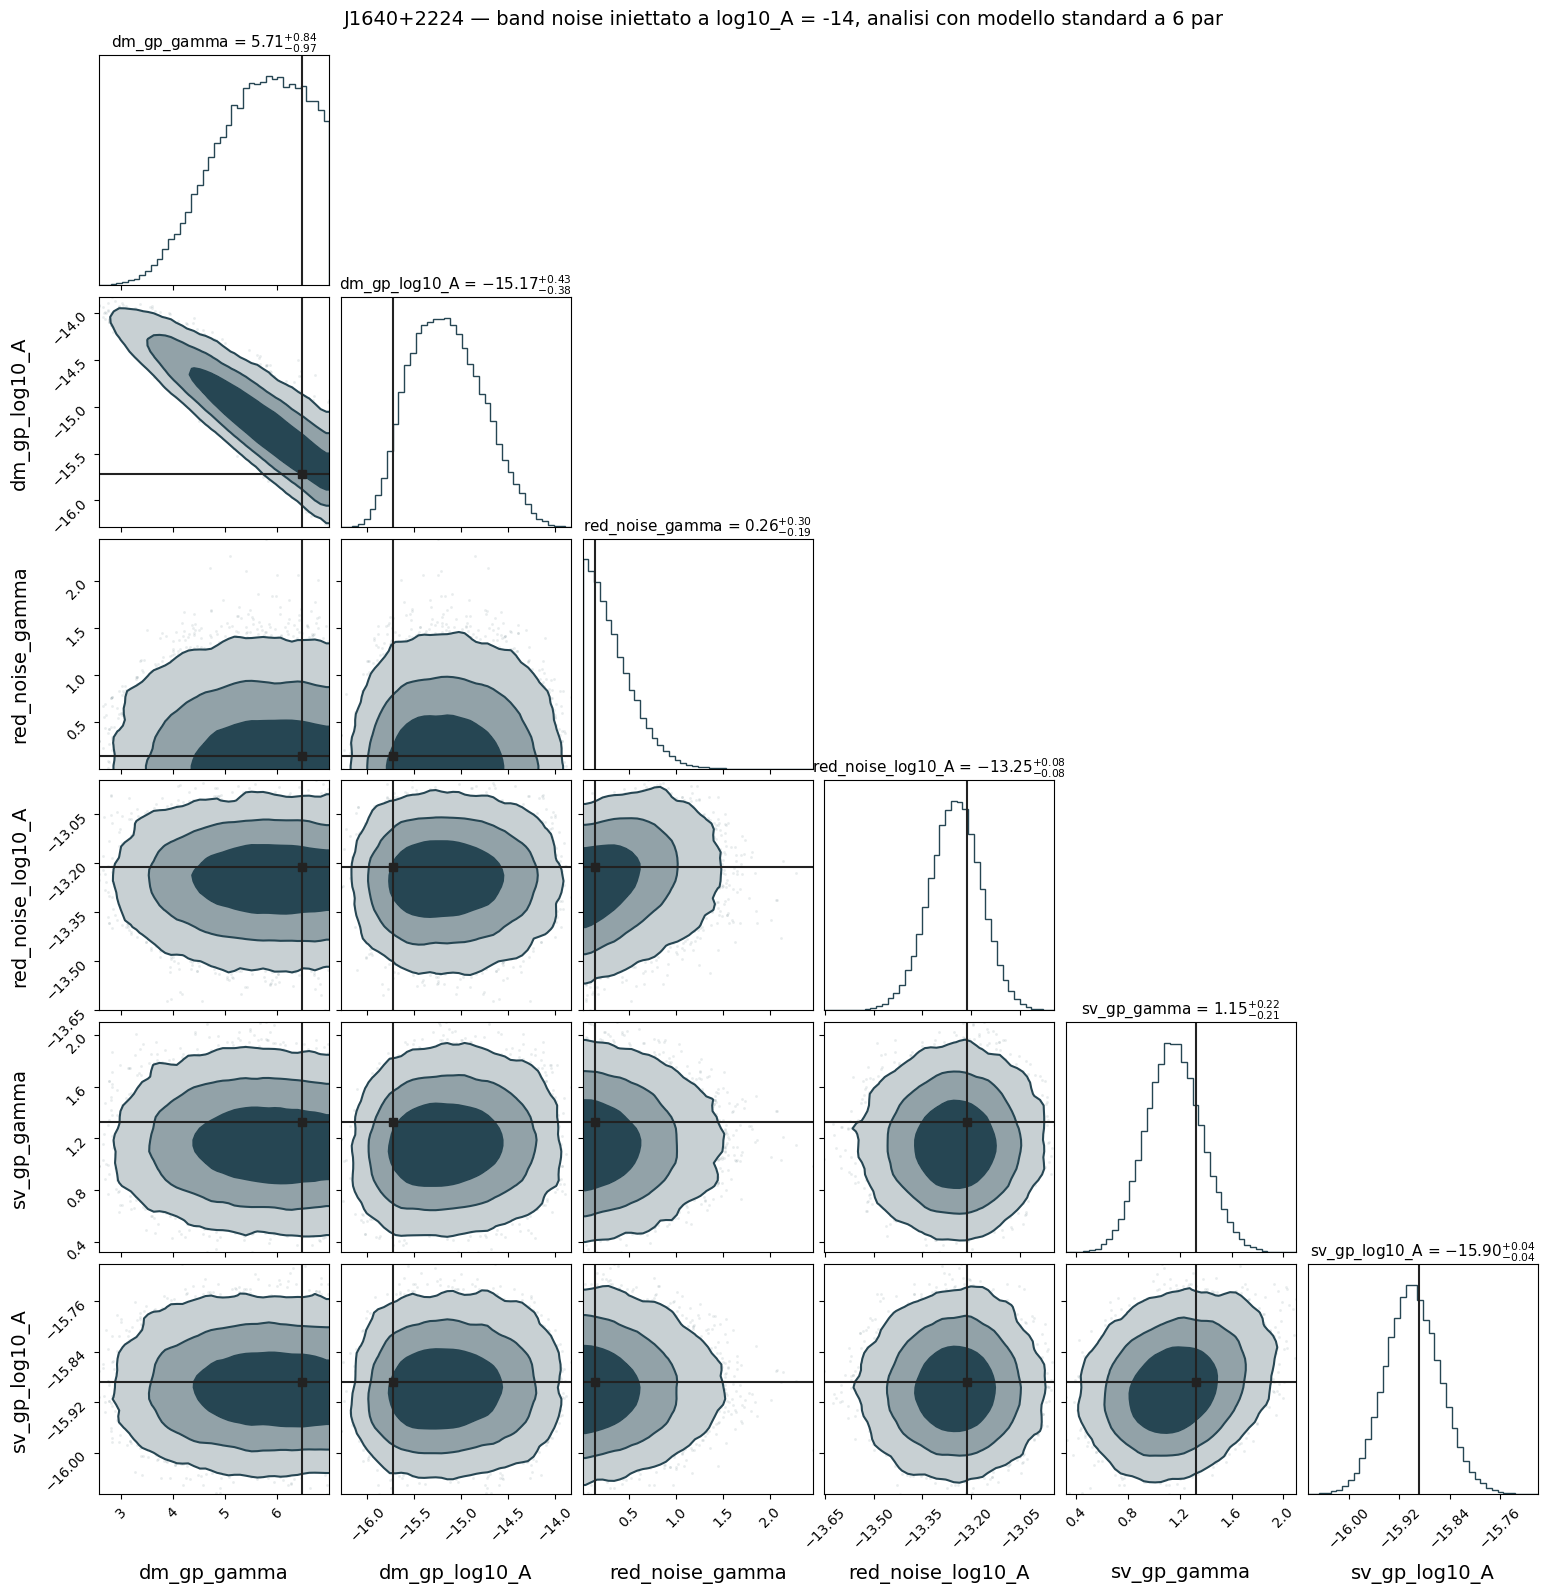

In [37]:
import corner

truth_values = [truths_bn[p] for p in logL_bn140.params]
clean_labels = [name.replace('J1640+2224_', '') for name in logL_bn140.params]

fig = corner.corner(
    chain_bn140,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 11},
    hist_kwargs={'density': True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    bins=40,
    color='#264653',
)
fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise iniettato a log10_A = -14, analisi con modello standard a 6 par',
             fontsize=14, y=1.00)
fig.savefig('corner_sim_bn_A140_standard.png', dpi=150, bbox_inches='tight')

### Confronto con la stessa analisi su dati SENZA band noise

`test_sim_sv44_alpha44/` e l analisi a 6 parametri con alpha = 4.4 di `sim_data_noise_sv44/`, cioe gli
stessi valori veri ma **senza** band noise nei dati. Lo spostamento fra le due posteriori e l effetto
del band noise.

**Avvertenza da tenere a mente leggendo il confronto.** Le due simulazioni hanno un numero diverso di
componenti GP (3 contro 4), quindi `gml.sample` ha estratto numeri casuali diversi: non sono la stessa
realizzazione con il band noise aggiunto sopra, sono due realizzazioni diverse. Parte della differenza
che vedrai e rumore di realizzazione, non effetto del band noise. Per un confronto davvero controllato
serve la baseline appaiata a `log10_A = -30` descritta nella cella raw di
`Simulations_bandnoise_A140_sv44.ipynb`.


senza band noise: 75001 campioni, shape (75001, 6)

parametro                   vero |      senza BN nei dati |        con BN nei dati
dm_gp_gamma                6.471 |    5.043 [  3.92,  6.18] |    5.709 [  4.74,  6.55]
dm_gp_log10_A            -15.723 |  -14.955 [-15.41,-14.53] |  -15.175 [-15.55,-14.75]
red_noise_gamma            0.132 |    0.217 [  0.06,  0.47] |    0.262 [  0.08,  0.57]
red_noise_log10_A        -13.213 |  -13.240 [-13.32,-13.16] |  -13.249 [-13.33,-13.17]
sv_gp_gamma                1.326 |    1.422 [  1.24,  1.62] |    1.152 [  0.94,  1.37]
sv_gp_log10_A            -15.888 |  -15.811 [-15.85,-15.77] |  -15.899 [-15.94,-15.85]


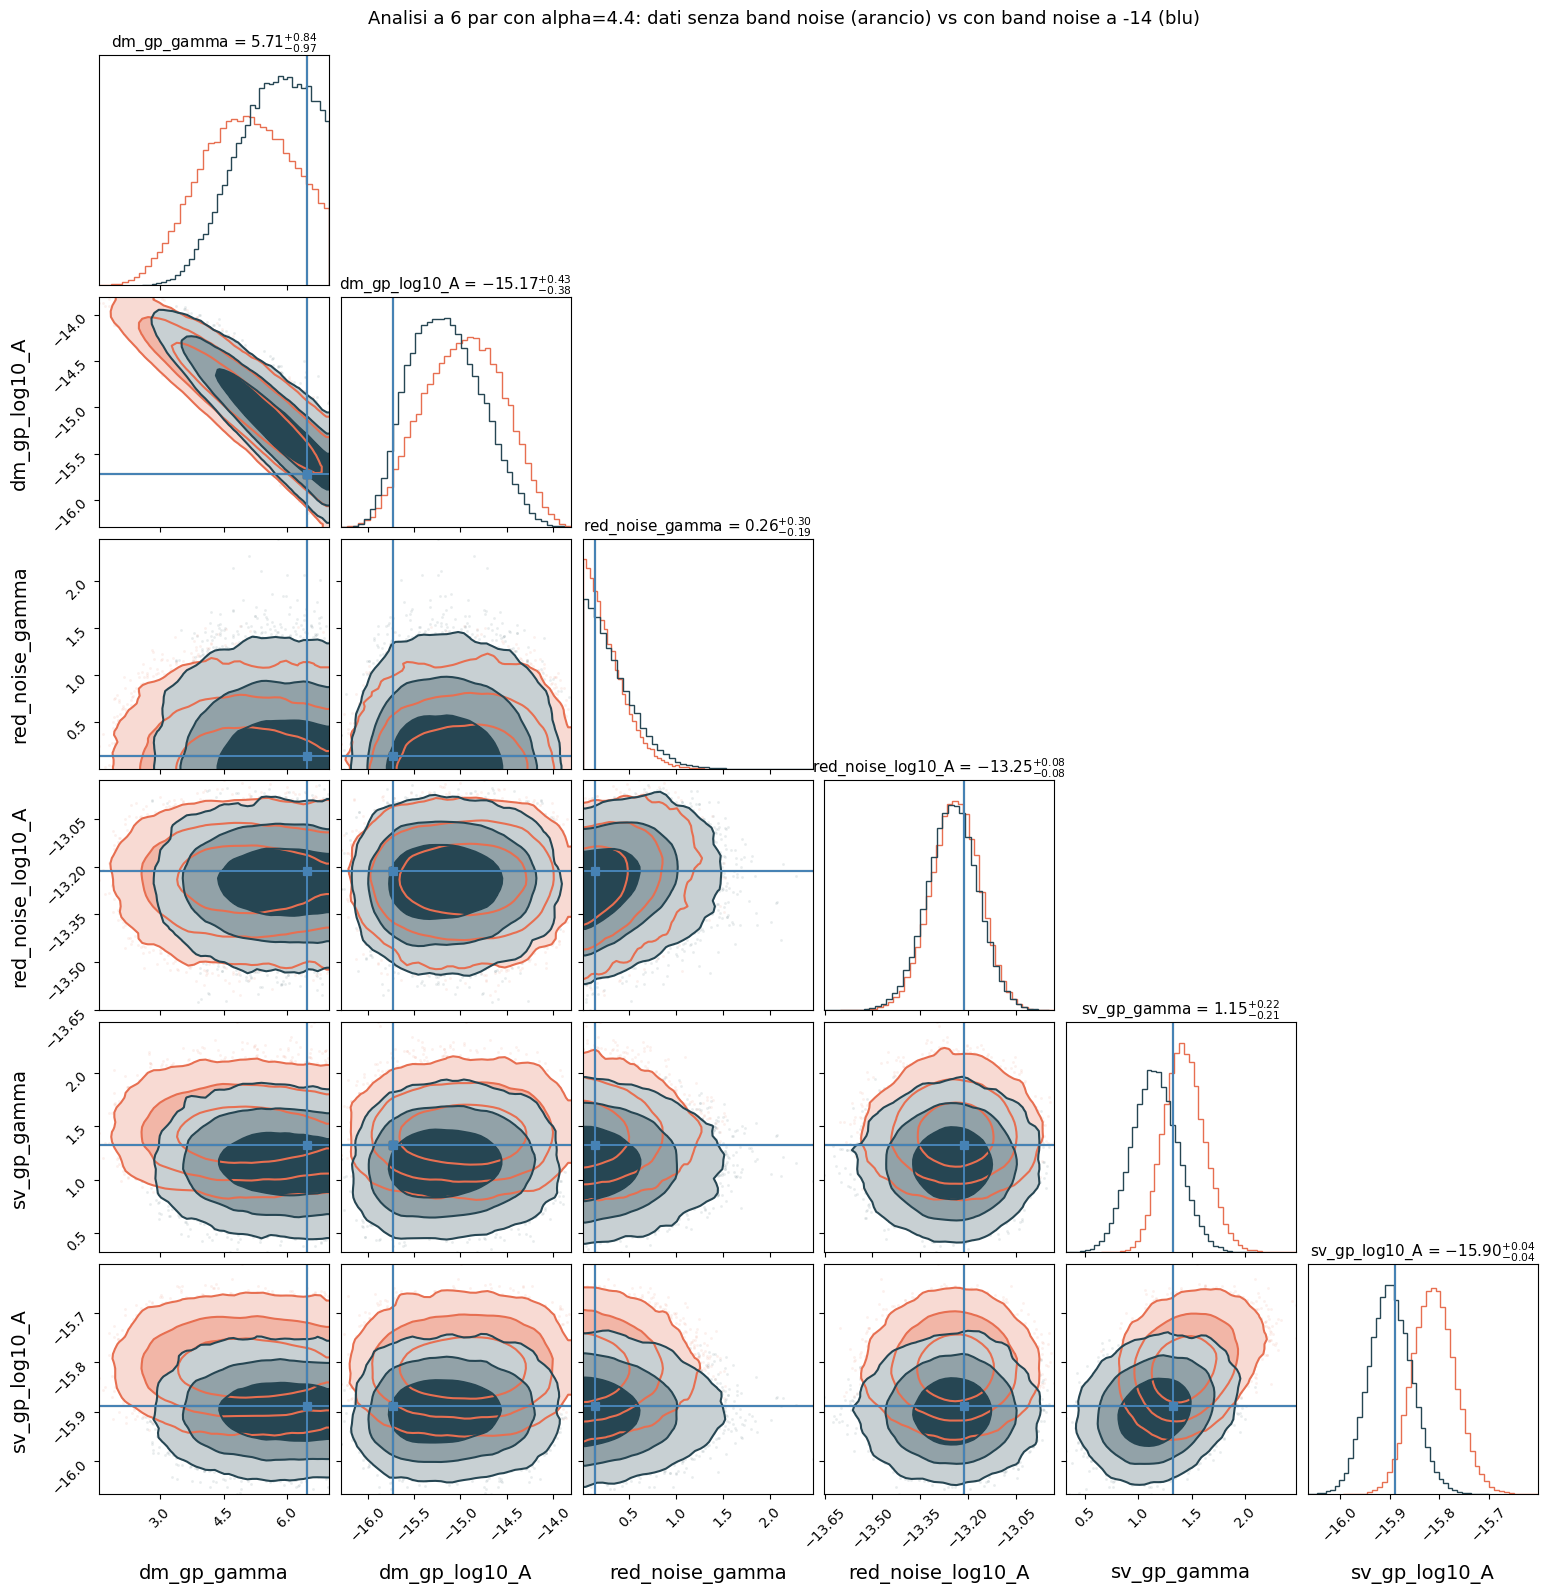

In [38]:
path_senza = './test_sim_sv44_alpha44/chain_1.txt'

if not os.path.exists(path_senza):
    print('catena senza band noise assente, confronto saltato:', path_senza)
else:
    chain_senza = np.loadtxt(path_senza)
    n_s = len(chain_senza)
    chain_senza = chain_senza[n_s//4:, :-4]
    print(f'senza band noise: {len(chain_senza)} campioni, shape {chain_senza.shape}')

    print(f"\n{'parametro':22s} {'vero':>9s} | {'senza BN nei dati':>22s} | {'con BN nei dati':>22s}")
    for i, name in enumerate(logL_bn140.params):
        a16, a50, a84 = np.percentile(chain_senza[:, i], [16, 50, 84])
        b16, b50, b84 = np.percentile(chain_bn140[:, idx[name]], [16, 50, 84])
        print(f"{name.replace('J1640+2224_', ''):22s} {truths_bn[name]:9.3f} | "
              f"{a50:8.3f} [{a16:6.2f},{a84:6.2f}] | {b50:8.3f} [{b16:6.2f},{b84:6.2f}]")

    fig = corner.corner(
        chain_senza, labels=clean_labels, truths=truth_values, truth_color='#222222',
        show_titles=True, title_fmt='.2f',
        label_kwargs={'fontsize': 14}, title_kwargs={'fontsize': 11},
        hist_kwargs={'density': True}, fill_contours=True,
        levels=(0.68, 0.95, 0.997), smooth=1.0, bins=40, color='#E76F51',
    )
    corner.corner(
        chain_bn140, labels=clean_labels, truths=truth_values,
        show_titles=True, title_fmt='.2f',
        label_kwargs={'fontsize': 14}, title_kwargs={'fontsize': 11},
        hist_kwargs={'density': True}, fill_contours=True,
        levels=(0.68, 0.95, 0.997), smooth=1.0, bins=40, color='#264653', fig=fig,
    )
    fig.set_size_inches(16, 16)
    fig.suptitle('Analisi a 6 par con alpha=4.4: dati senza band noise (arancio) vs con band noise a -14 (blu)',
                 fontsize=13, y=1.00)
    fig.savefig('corner_sim_bn_A140_senza_vs_con.png', dpi=150, bbox_inches='tight')

## Cosa guardare

1. **La colonna `shift`.** Il parametro che si allontana di piu dal valore vero e quello che sta
   assorbendo il band noise. Se e `sv_gp_log10_A`, un sistematico di banda si traveste da scattering;
   se e `dm_gp`, si traveste da variazione di DM. In entrambi i casi e il meccanismo che sospetti nei
   dati reali, qui visto dove la verita e nota.
2. **Se nessuno shift supera 1 sigma**, a log10_A = -14 il band noise non produce bias rilevabile con
   questo modello, e le ampiezze piu piccole (-14.5, -15) lo produrranno ancora meno: lo sapresti
   prima di spenderci altre run.
3. **La forma della posteriore.** Oltre allo spostamento della mediana, guarda se compaiono code o
   strutture a L nei pannelli `dm_gp` / `sv_gp` che nella simulazione senza band noise non c erano.
   Sono le stesse strutture che vedi nei dati reali.
4. **Il passo successivo** e il notebook 17, con il band noise anche nella recovery: li la domanda
   diventa se si recuperano `log10_A = -14` e `gamma = 3`, e se il band noise e separabile dallo
   scattering.


# Band noise simulato con 50 componenti

Stessa analisi delle sezioni sopra (modello standard a 6 parametri, alpha = 4.4, **nessun band noise nel modello**),
ma sui dati simulati con **50 componenti di Fourier** per il band noise invece di 40.

Dati: `sim_data_noise_bn_A140_sv44prova_con50/`, generati da `Simulations_bandnoise_A140_sv44.ipynb`
(stessi valori veri, stesso seed `key(1)`). Le sezioni sopra restano la run a 40 componenti.

Tutte le variabili di questa sezione hanno il suffisso `_50`, cosi rieseguire una sezione non sporca l altra.
Le prior (`log_prior_bn140`, `prior_draw_bn140`) e `truths_bn` si riusano: i parametri sono gli stessi.


In [39]:
bn50_psr = ds.pulsar.Pulsar.read_feather('sim_data_noise_bn_A140_sv44prova_con50/J1640+2224')
print('nome  :', bn50_psr.name)
print('N_TOA :', len(bn50_psr.toas))

# stessa maschera LOFAR di sopra (stesse ToA, stessi backend)
sel_50 = ds.lofar_backends(bn50_psr)
mask_lofar_50 = np.any(np.vstack([np.asarray(m, dtype=bool) for m in sel_50.values()]), axis=0)
assert np.array_equal(mask_lofar_50, mask_lofar), 'la selezione LOFAR non coincide con quella della run a 40'
print(f'ToA LOFAR: {mask_lofar_50.sum()} su {len(bn50_psr.toas)}')

print()
print(f"{'':22s} {'sim 50':>12s} {'sim 40':>12s} {'reali':>12s}")
for etichetta, m in [('tutte', np.ones(len(bn50_psr.toas), bool)),
                     ('LOFAR (121-185 MHz)', mask_lofar_50),
                     ('resto (>1 GHz)', ~mask_lofar_50)]:
    print(f'{etichetta:22s} {np.std(bn50_psr.residuals[m]):12.3e} '
          f'{np.std(bn_psr.residuals[m]):12.3e} {np.std(psr.residuals[m]):12.3e}')


nome  : J1640+2224
N_TOA : 6777
ToA LOFAR: 5232 su 6777

                             sim 50       sim 40        reali
tutte                     8.115e-05    7.385e-05    4.973e-05
LOFAR (121-185 MHz)       9.077e-05    8.388e-05    5.644e-05
resto (>1 GHz)            8.338e-06    8.334e-06    7.645e-06


### Check: le due simulazioni condividono la realizzazione?

Il seed e lo stesso (`key(1)`), ma con 50 componenti il vettore di coefficienti casuali ha una dimensione
diversa, quindi la realizzazione di red noise, DM e scattering potrebbe essere cambiata anch essa.
Fuori dalla banda LOFAR il band noise non c e: se li le due simulazioni coincidono, differiscono solo
per il band noise; altrimenti il confronto 40 vs 50 mescola l effetto delle componenti con il rumore
di realizzazione.


In [40]:
d_40_50 = bn50_psr.residuals - bn_psr.residuals

print(f'differenza sulle ToA LOFAR : std = {np.std(d_40_50[mask_lofar_50]):.3e} s   max|d| = {np.max(np.abs(d_40_50[mask_lofar_50])):.3e}')
print(f'differenza sulle altre ToA : std = {np.std(d_40_50[~mask_lofar_50]):.3e} s   max|d| = {np.max(np.abs(d_40_50[~mask_lofar_50])):.3e}')
print(f'(per scala: std residui simulati fuori LOFAR = {np.std(bn_psr.residuals[~mask_lofar_50]):.3e} s)')
print()
if np.max(np.abs(d_40_50[~mask_lofar_50])) < 1e-15:
    print('OK: fuori da LOFAR le due simulazioni coincidono -> stessa realizzazione di RN, DM e scattering.')
else:
    print('ATTENZIONE: fuori da LOFAR le due simulazioni sono diverse -> realizzazioni diverse.')
    print('    Le differenze fra le posteriori 40 e 50 includono anche il rumore di realizzazione.')


differenza sulle ToA LOFAR : std = 7.403e-05 s   max|d| = 2.679e-04
differenza sulle altre ToA : std = 6.789e-07 s   max|d| = 2.013e-06
(per scala: std residui simulati fuori LOFAR = 8.334e-06 s)

ATTENZIONE: fuori da LOFAR le due simulazioni sono diverse -> realizzazioni diverse.
    Le differenze fra le posteriori 40 e 50 includono anche il rumore di realizzazione.


## Modello standard a 6 parametri sui dati a 50 componenti

Identico a `model_bn140`, ma costruito su `bn50_psr`: la likelihood contiene i residui, quindi va
ricostruita e non si puo riusare `logL_bn140`.


In [41]:
model_bn140_50 = [bn50_psr.residuals]
model_bn140_50 += [ds.makegp_timing(bn50_psr, svd=True)]
model_bn140_50 += [ds.makenoise_measurement(bn50_psr, bn50_psr.noisedict, tnequad=True, ecorr=True)]
model_bn140_50.append(ds.makegp_fourier(bn50_psr, ds.powerlaw, bn50_psr.noisedict[bn50_psr.name + '_red_components'],
                                        T=ds.getspan(bn50_psr), name='red_noise'))
model_bn140_50.append(ds.makegp_fourier(bn50_psr, ds.powerlaw, bn50_psr.noisedict[bn50_psr.name + '_dm_components'],
                                        T=ds.getspan(bn50_psr), name='dm_gp',
                                        fourierbasis=ds.make_dmfourierbasis(alpha=2.0, tndm=False)))
model_bn140_50.append(ds.makegp_fourier(bn50_psr, ds.powerlaw, bn50_psr.noisedict[bn50_psr.name + '_chrom_components'],
                                        T=ds.getspan(bn50_psr), name='sv_gp',
                                        fourierbasis=ds.make_dmfourierbasis(alpha=4.4, tndm=False)))

logL_bn140_50 = ds.PulsarLikelihood(model_bn140_50).logL

# stesso ORDINE dei parametri della run a 40: serve perche le prior vengono riusate
assert list(logL_bn140_50.params) == list(logL_bn140.params), f'ordine diverso: {logL_bn140_50.params}'
print('OK: 6 parametri, stesso ordine della run a 40, nessun band noise nel modello')
logL_bn140_50.params


OK: 6 parametri, stesso ordine della run a 40, nessun band noise nel modello


['J1640+2224_dm_gp_gamma',
 'J1640+2224_dm_gp_log10_A',
 'J1640+2224_red_noise_gamma',
 'J1640+2224_red_noise_log10_A',
 'J1640+2224_sv_gp_gamma',
 'J1640+2224_sv_gp_log10_A']

In [42]:
@jax.jit
def _jit_logL_bn140_50(params_array):
    return logL_bn140_50(dict(zip(logL_bn140_50.params, params_array)))

def log_likelihood_bn140_50(x):
    x = np.asarray(x, dtype=np.float64)
    return float(np.array(_jit_logL_bn140_50(jnp.array(x))))

# prior riusate dalla run a 40 (stessi parametri, stesso ordine)
x0_bn140_50 = prior_draw_bn140()
print('x0 =', x0_bn140_50)
print('logL iniziale =', log_likelihood_bn140_50(x0_bn140_50))

start = time.time()
for _ in range(20):
    log_likelihood_bn140_50(x0_bn140_50)
dt = (time.time() - start) / 20
print(f'una valutazione = {dt*1e3:.1f} ms  ->  10^6 iterazioni ~ {dt*1e6/3600:.1f} ore (solo likelihood)')


x0 = [  5.01547099 -11.40763721   5.77019211 -15.72807339   1.4766333
 -13.275413  ]
logL iniziale = 67536.44728948871
una valutazione = 1.4 ms  ->  10^6 iterazioni ~ 0.4 ore (solo likelihood)


In [43]:
sampler_bn140_50 = ptmcmc(
    ndim=len(logL_bn140_50.params),
    logl=log_likelihood_bn140_50,
    logp=log_prior_bn140,
    cov=np.eye(len(logL_bn140_50.params)) * 0.001,
    outDir='./test_sim_bn_A140_50comp/',   # cartella NUOVA: con resume=True non riprende la run a 40
    resume=True
)


### Sampling (50 componenti)

Come sopra: eseguire **una sola volta**, poi per rifare i grafici ripartire dalla cella che legge `chain_1.txt`.


In [44]:
ESEGUI_SAMPLING_50 = True   # True solo per (ri)lanciare davvero il campionamento

if ESEGUI_SAMPLING_50:
    print("Starting sampling (band noise 50 componenti iniettato a -14, analisi con modello STANDARD a 6 par)...")
    sampler_bn140_50.sample(x0_bn140_50, Niter=1000000, thin=10)
else:
    print('sampling saltato: mettere ESEGUI_SAMPLING_50 = True per lanciarlo')


Starting sampling (band noise 50 componenti iniettato a -14, analisi con modello STANDARD a 6 par)...
Finished 1.00 percent (1.00 percent of new work) in 14.249393 s Acceptance rate = 0.2136Adding DE jump with weight 20
Finished 100.00 percent (100.00 percent of new work) in 7549.716554 s Acceptance rate = 0.367317
Run Complete


## Catena e risultati (50 componenti)


In [45]:
chain_path_50 = './test_sim_bn_A140_50comp/chain_1.txt'

if not os.path.exists(chain_path_50):
    raise FileNotFoundError(
        f'catena non trovata: {chain_path_50}\n'
        'Mettere ESEGUI_SAMPLING_50 = True nella cella sopra e lanciare il sampling.'
    )

chain_bn140_50 = np.loadtxt(chain_path_50)
n_tot_50 = len(chain_bn140_50)
chain_bn140_50 = chain_bn140_50[n_tot_50//4:, :-4]   # 25% di burn-in, via le 4 colonne diagnostiche
print(f'righe nel file: {n_tot_50}  ->  campioni usati: {len(chain_bn140_50)}  ({100*n_tot_50/100000:.1f}% della run completa)')

tau_50 = emcee.autocorr.integrated_time(chain_bn140_50, has_walkers=False, quiet=True)
ess_50 = int(len(chain_bn140_50) / tau_50.max())
print('tau =', dict(zip([p.replace('J1640+2224_', '') for p in logL_bn140_50.params], np.round(tau_50, 1))))
print('Effective sample size =', ess_50)


righe nel file: 100001  ->  campioni usati: 75001  (100.0% della run completa)
tau = {'dm_gp_gamma': np.float64(4.0), 'dm_gp_log10_A': np.float64(4.0), 'red_noise_gamma': np.float64(4.1), 'red_noise_log10_A': np.float64(3.2), 'sv_gp_gamma': np.float64(3.8), 'sv_gp_log10_A': np.float64(3.1)}
Effective sample size = 18501


In [46]:
# shift dai valori veri in unita di sigma della posteriore (stesso ordine di colonne: si riusa idx)
print(f"{'parametro':22s} {'vero':>9s} {'mediana':>9s} {'[16, 84]':>20s} {'shift':>8s}")
for name in logL_bn140_50.params:
    col = chain_bn140_50[:, idx[name]]
    q16, q50, q84 = np.percentile(col, [16, 50, 84])
    sigma = 0.5 * (q84 - q16)
    vero = truths_bn[name]
    shift = (q50 - vero) / sigma if sigma > 0 else np.nan
    flag = '  <-- assorbe il band noise?' if abs(shift) > 1.5 else ''
    print(f"{name.replace('J1640+2224_', ''):22s} {vero:9.3f} {q50:9.3f} "
          f"[{q16:8.3f},{q84:8.3f}] {shift:7.2f}s{flag}")


parametro                   vero   mediana             [16, 84]    shift
dm_gp_gamma                6.471     5.352 [   4.091,   6.442]   -0.95s
dm_gp_log10_A            -15.723   -15.076 [ -15.568, -14.550]    1.27s
red_noise_gamma            0.132     0.491 [   0.179,   0.876]    1.03s
red_noise_log10_A        -13.213   -13.190 [ -13.264, -13.116]    0.31s
sv_gp_gamma                1.326     1.276 [   1.068,   1.496]   -0.23s
sv_gp_log10_A            -15.888   -15.934 [ -15.976, -15.889]   -1.04s


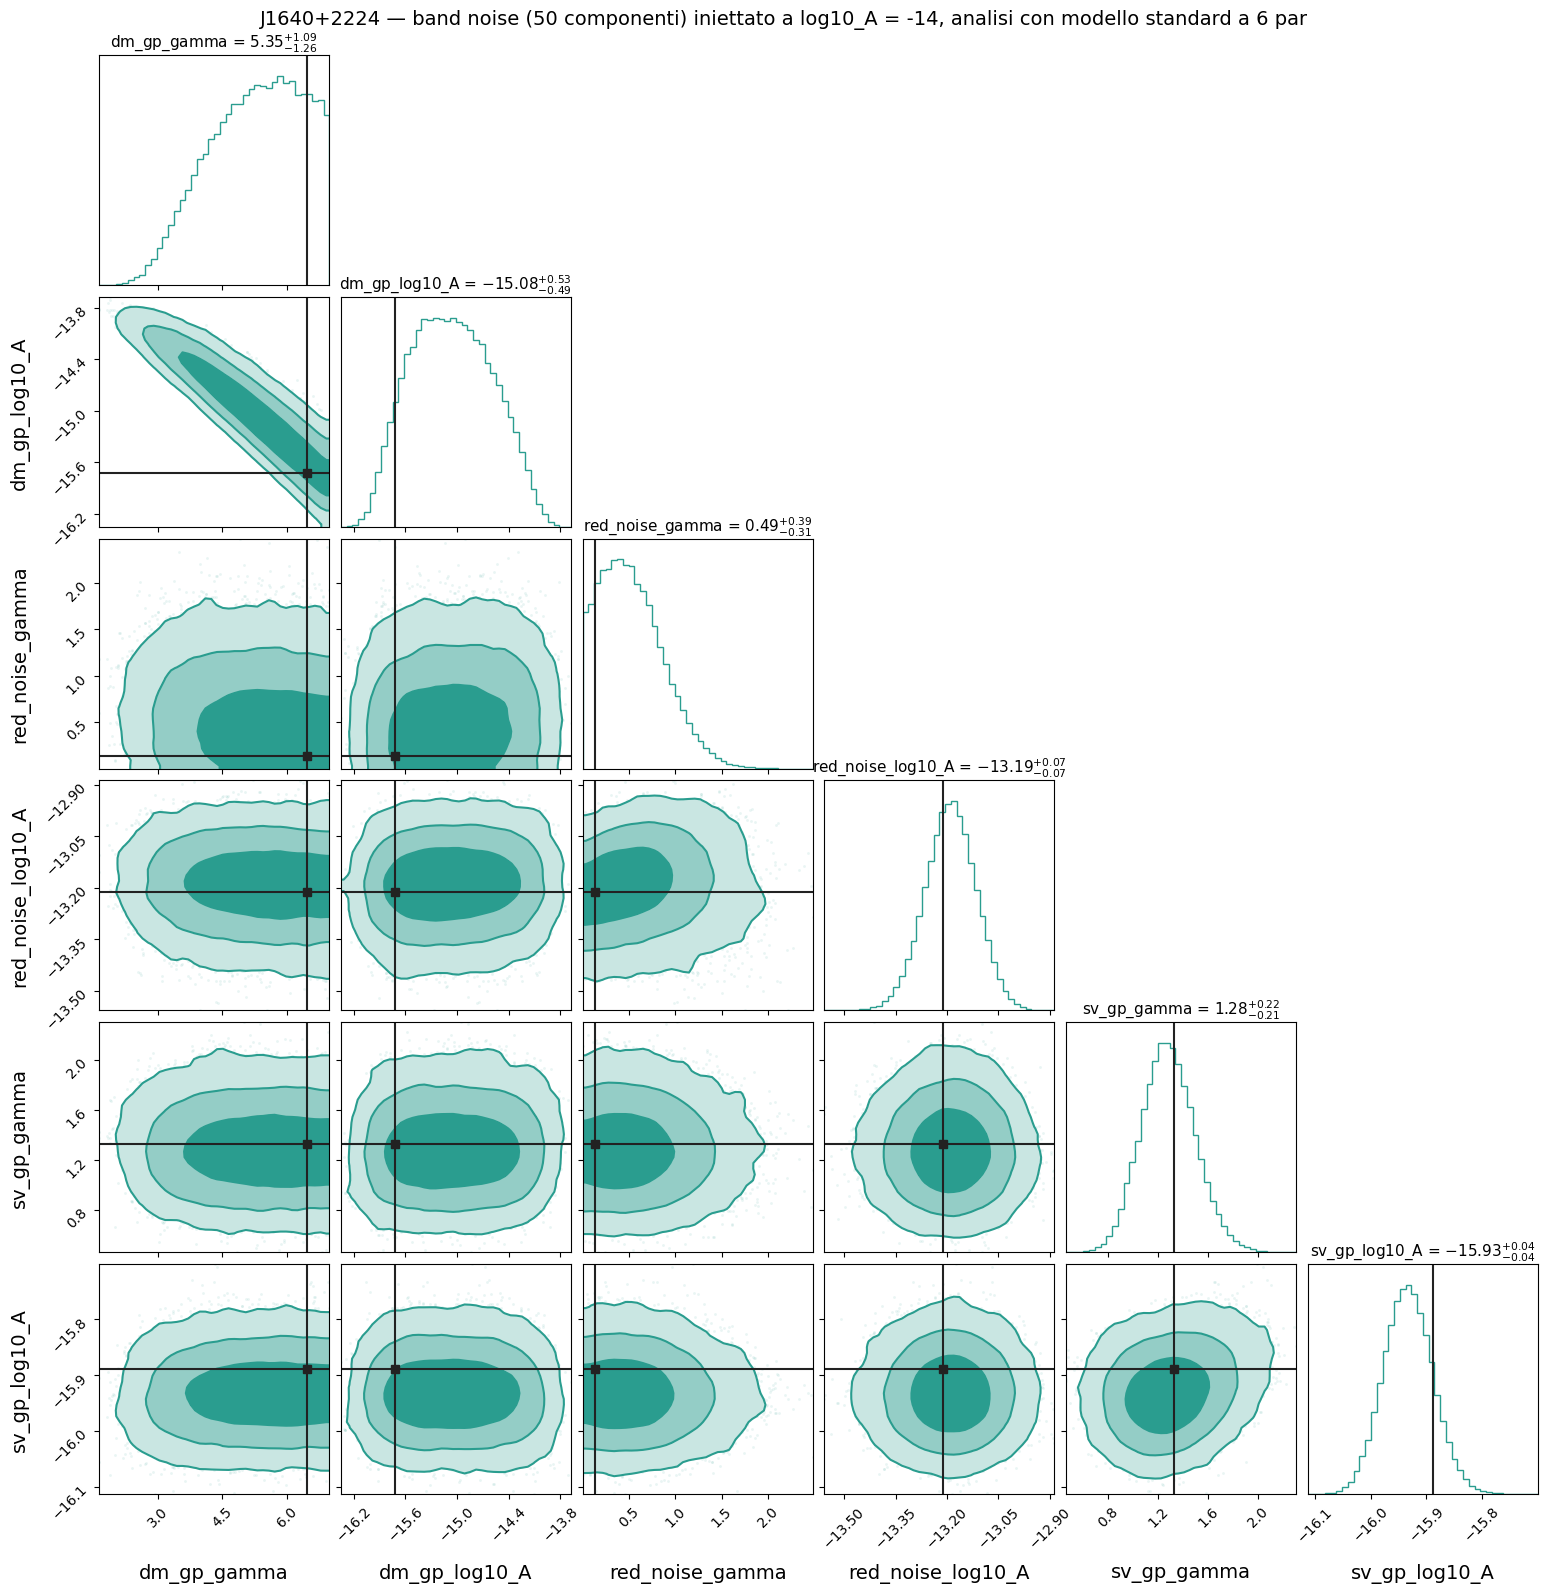

In [47]:
fig = corner.corner(
    chain_bn140_50,
    labels=clean_labels,
    truths=truth_values,
    truth_color='#222222',
    show_titles=True,
    title_fmt='.2f',
    label_kwargs={'fontsize': 14},
    title_kwargs={'fontsize': 11},
    hist_kwargs={'density': True},
    fill_contours=True,
    levels=(0.68, 0.95, 0.997),
    smooth=1.0,
    bins=40,
    color='#2A9D8F',
)
fig.set_size_inches(16, 16)
fig.suptitle('J1640+2224 — band noise (50 componenti) iniettato a log10_A = -14, analisi con modello standard a 6 par',
             fontsize=14, y=1.00)
fig.savefig('corner_sim_bn_A140_50comp_standard.png', dpi=150, bbox_inches='tight')


## Confronto 40 vs 50 componenti

Stessa analisi, stessi valori veri: cambia solo il numero di componenti del band noise nella simulazione.
Se le posteriori sono compatibili, il risultato e robusto rispetto a questa scelta.

Per il corner sovrapposto: range comune dai percentili 0.5-99.5 di entrambe le catene, e ogni campione
pesato 1/N, cosi gli istogrammi 1D delle due catene sono confrontabili (nel percorso `fig=fig` di
corner 2.2.3 `density` non viene applicato).


In [48]:
print(f"{'parametro':22s} {'vero':>9s} | {'40 componenti':>24s} | {'50 componenti':>24s} | {'diff/sigma':>10s}")
for name in logL_bn140_50.params:
    a16, a50, a84 = np.percentile(chain_bn140[:, idx[name]], [16, 50, 84])
    b16, b50, b84 = np.percentile(chain_bn140_50[:, idx[name]], [16, 50, 84])
    sig = np.hypot(0.5 * (a84 - a16), 0.5 * (b84 - b16))
    print(f"{name.replace('J1640+2224_', ''):22s} {truths_bn[name]:9.3f} | "
          f"{a50:8.3f} [{a16:6.2f},{a84:6.2f}] | {b50:8.3f} [{b16:6.2f},{b84:6.2f}] | {(b50 - a50)/sig:10.2f}")


parametro                   vero |            40 componenti |            50 componenti | diff/sigma
dm_gp_gamma                6.471 |    5.709 [  4.74,  6.55] |    5.352 [  4.09,  6.44] |      -0.24
dm_gp_log10_A            -15.723 |  -15.175 [-15.55,-14.75] |  -15.076 [-15.57,-14.55] |       0.15
red_noise_gamma            0.132 |    0.262 [  0.08,  0.57] |    0.491 [  0.18,  0.88] |       0.54
red_noise_log10_A        -13.213 |  -13.249 [-13.33,-13.17] |  -13.190 [-13.26,-13.12] |       0.55
sv_gp_gamma                1.326 |    1.152 [  0.94,  1.37] |    1.276 [  1.07,  1.50] |       0.41
sv_gp_log10_A            -15.888 |  -15.899 [-15.94,-15.85] |  -15.934 [-15.98,-15.89] |      -0.56


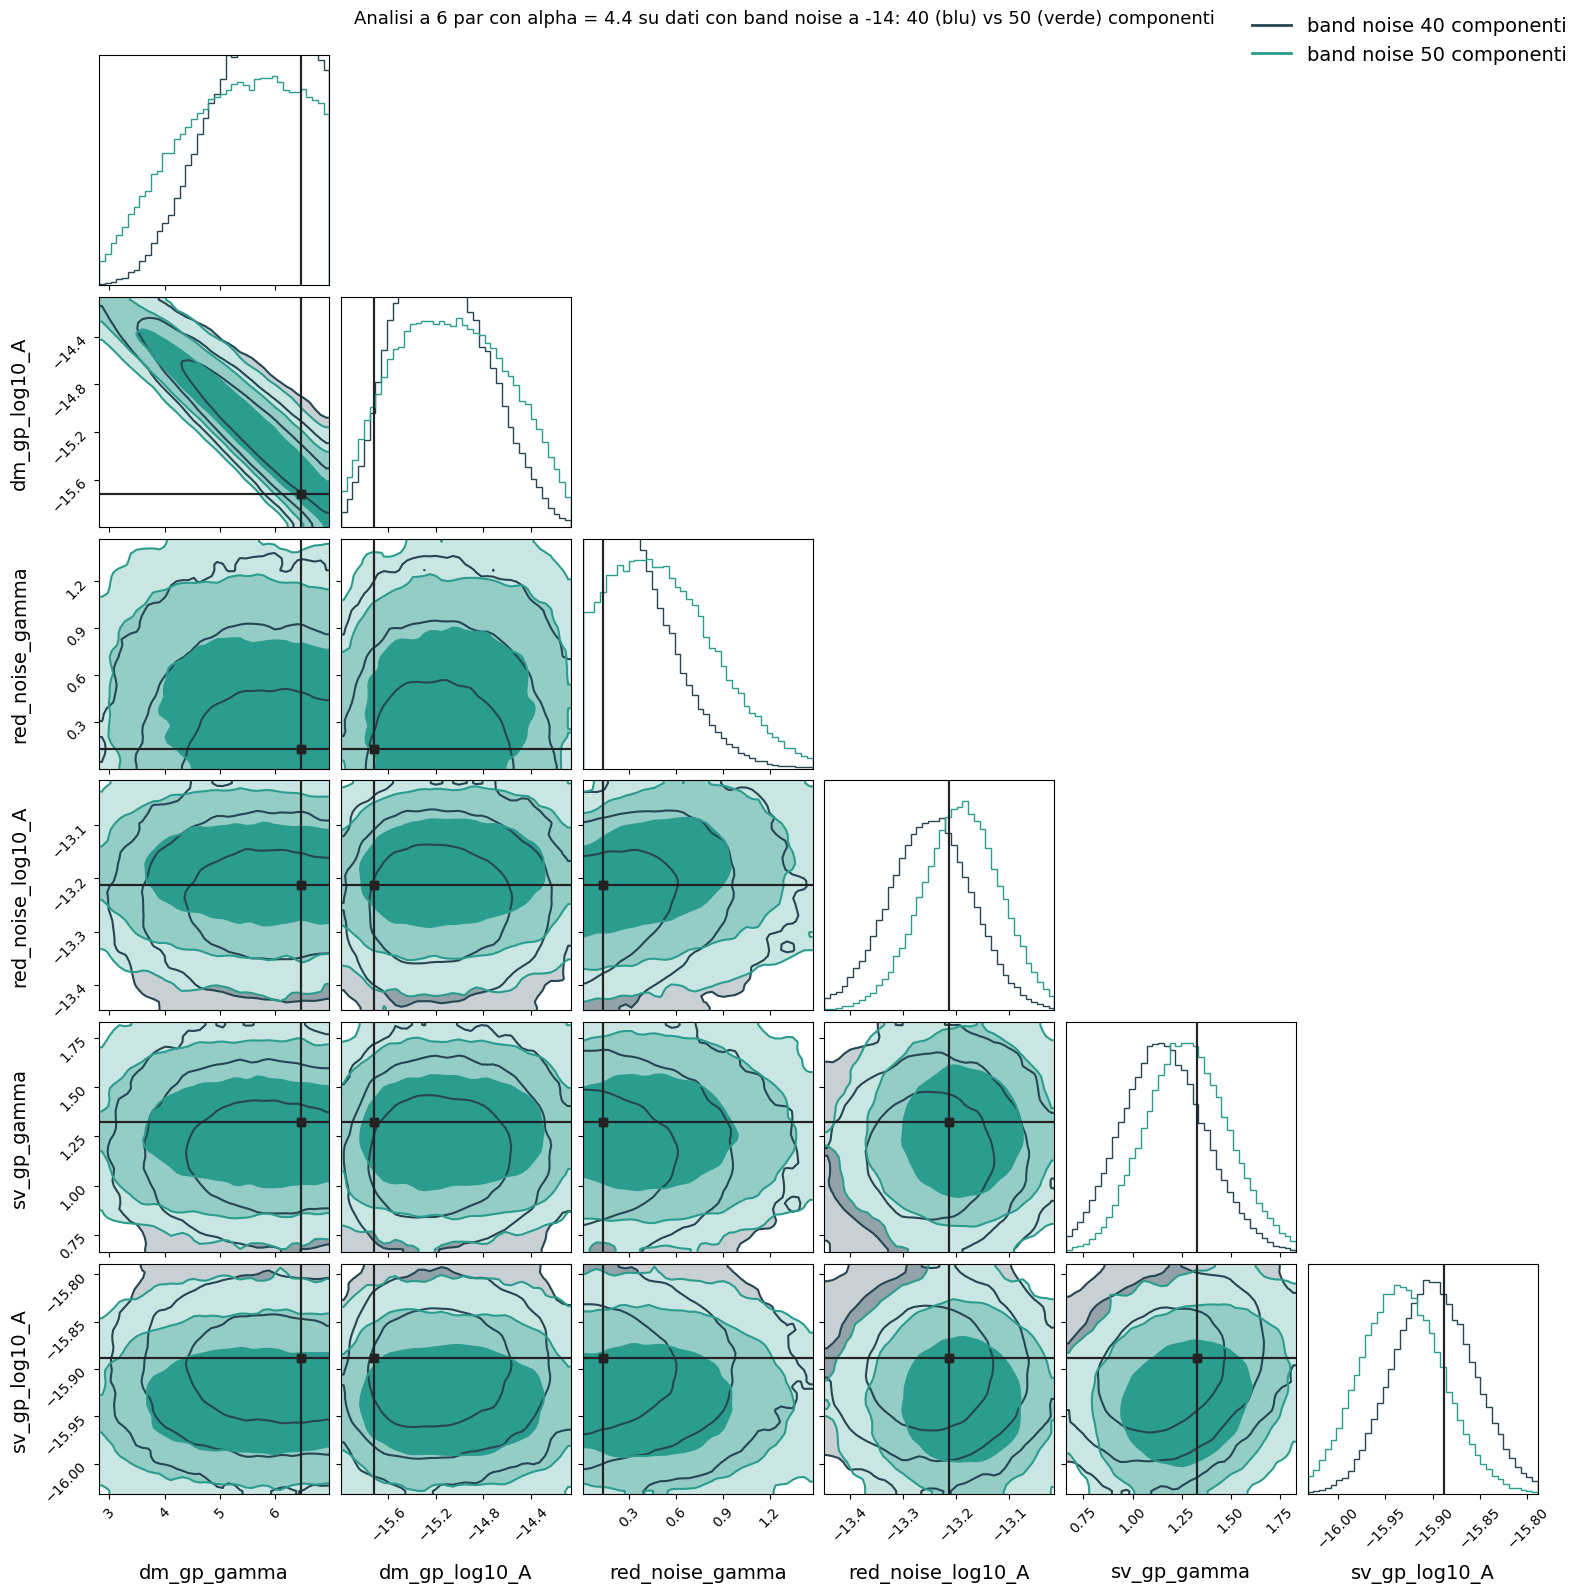

In [49]:
# range comune ai due run
ranges_40_50 = []
for i in range(chain_bn140.shape[1]):
    both = np.concatenate([chain_bn140[:, i], chain_bn140_50[:, i]])
    ranges_40_50.append(tuple(np.percentile(both, [0.5, 99.5])))

kw_40_50 = dict(labels=clean_labels, truths=truth_values, truth_color='#222222',
                range=ranges_40_50, show_titles=False,
                label_kwargs={'fontsize': 14}, plot_datapoints=False,
                fill_contours=True, levels=(0.68, 0.95, 0.997), smooth=1.0, bins=40)

fig = corner.corner(chain_bn140, weights=np.ones(len(chain_bn140)) / len(chain_bn140),
                    color='#264653', **kw_40_50)
corner.corner(chain_bn140_50, weights=np.ones(len(chain_bn140_50)) / len(chain_bn140_50),
              color='#2A9D8F', fig=fig, **kw_40_50)

from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color='#264653', lw=2, label='band noise 40 componenti'),
                    Line2D([], [], color='#2A9D8F', lw=2, label='band noise 50 componenti')],
           loc='upper right', fontsize=14, frameon=False)
fig.set_size_inches(16, 16)
fig.suptitle('Analisi a 6 par con alpha = 4.4 su dati con band noise a -14: 40 (blu) vs 50 (verde) componenti',
             fontsize=13, y=1.00)
fig.savefig('corner_sim_bn_A140_40_vs_50comp.png', dpi=150, bbox_inches='tight')
